# Occupancy Volumes

A neural field represents a 3D shape as its occupancy, a function from a point's
coordinates to whether the point lies inside. This notebook fits the Stanford
Thai statue, voxelized at 256 samples per unit length, under the occupancy
benchmark's protocol: about 131k parameters each, and 1000 steps of Adam, each
on 2^18 = 262,144 random voxels, with a cosine-annealed learning rate. It compares
FUTON, with a sinc and a cosine basis, against five representative baselines
of the benchmark: RFF (Fourier features), SIREN and FINER (periodic
activations), Instant-NGP (a hash grid) and TensoRF (a grid factorization, in
its VM form). Every setting is that of `configs/occupancy.yaml`, which holds
every model of the benchmark.

## Setup

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from matplotlib.ticker import (
    FixedLocator,
    MaxNLocator,
    MultipleLocator,
    NullFormatter,
    StrMethodFormatter,
)
from matplotlib_inline.backend_inline import set_matplotlib_formats
from PIL import Image

import neurofield as nf

set_matplotlib_formats("retina")  # sharp figures on high-resolution screens
sns.set_theme(
    context="notebook", style="whitegrid", font_scale=0.85, rc={"grid.color": ".92"}
)

colorblind = sns.color_palette("colorblind")
# FUTON in black, its cosine basis dashed; the periodic activations in warm
# hues and the grids in cool ones.
PALETTE = {
    "FUTON (sinc)": "black",
    "FUTON (cosine)": "black",
    "RFF": colorblind[4],
    "SIREN": colorblind[1],
    "FINER": colorblind[3],
    "Instant-NGP": colorblind[2],
    "TensoRF": colorblind[0],
}
DASHES = {model: (4, 2) if model == "FUTON (cosine)" else "" for model in PALETTE}
# seaborn's own markers, each fixed to a model as its colour is
MARKERS = dict(zip(PALETTE, ["o", "X", (4, 0, 45), "P", (4, 0, 0), (4, 1, 0), "^"]))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


The plotting helpers: training time on a log axis, the metric on whole
decibels or half points, a summary table, images side by side, and
reconstructions above their errors.

In [2]:
NICE = [1, 2, 5, 10]  # tick steps: 1, 2 or 5 times a power of ten


def time_axis(ax, times):
    """Training time on a log axis, ticked 1, 2, 5, 10, ... in plain numbers."""
    low, high = times.min() / 1.1, times.max() * 1.1
    ax.set(xscale="log", xlim=(low, high), xlabel="Training time (s)")
    for subs in ((1, 2, 5), (1,)):
        ticks = [m * 10.0**k for k in range(-3, 6) for m in subs]
        ticks = [tick for tick in ticks if low <= tick <= high]
        if len(ticks) <= 7:
            break
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())


def metric_axis(ax, metric, low, high):
    """The metric's axis over [low, high]: whole decibels for a PSNR, half
    points for an IoU, which cannot pass 100."""
    if metric == "IoU (%)":
        low = np.floor(2 * low) / 2
        ax.set_ylim(low, min(max(np.ceil(2 * high) / 2, low + 0.5), 100))
        ax.yaxis.set_major_locator(MultipleLocator(0.5))
    else:
        low = np.floor(low)
        ax.set_ylim(low, max(np.ceil(high), low + 1))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=6, steps=NICE, integer=True))


def table(summary, formats, better):
    """The summary, each column in its format and, in each column of
    ``better`` ("higher" or "lower"), the best value bold and the second
    underlined."""

    def marks(column):
        rank = column.rank(method="min", ascending=better[column.name] == "lower")
        looks = {1: "font-weight: bold", 2: "text-decoration: underline"}
        return [looks.get(r, "") for r in rank]

    return (
        summary.style.format(formats, na_rep="")
        .apply(marks, subset=list(better))
        .hide(axis="index")
    )


def show(panels, ncols, width=11, **imshow):
    """Images side by side under their titles, in rows of ``ncols``, each
    drawn at the size of the first."""
    height, side = panels[0][1].shape[:2]
    nrows = -(-len(panels) // ncols)
    room = 0.45 if any("\n" in title for title, _ in panels) else 0.3
    fig, axes = plt.subplots(
        nrows,
        ncols,
        squeeze=False,
        layout="constrained",
        figsize=(width, nrows * (width / ncols * height / side + room)),
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, image) in zip(axes.flat, panels):
        ax.imshow(image, interpolation="nearest", **imshow)
        ax.set_title(title, fontsize=9)
    return fig


def compare(panels, label, width=11):
    """The reference and the reconstructions in a row under their titles
    (``panels``, the reference first), and beneath each reconstruction its
    absolute error, averaged over the colour channels; the errors share one
    scale, which saturates at their 99th percentile, and its colour bar
    stands beneath the reference."""
    reference = panels[0][1].astype(float)
    errors = [np.abs(image - reference).mean(-1) for _, image in panels[1:]]
    height, side = reference.shape[:2]
    ncols = len(panels)
    fig, axes = plt.subplots(
        2,
        ncols,
        layout="constrained",
        figsize=(width, 2 * width / ncols * height / side + 0.45),
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, image) in zip(axes[0], panels):
        ax.imshow(image, interpolation="nearest")
        ax.set_title(title, fontsize=9)
    vmax = np.percentile(np.concatenate([error.ravel() for error in errors]), 99)
    for ax, error in zip(axes[1, 1:], errors):
        maps = ax.imshow(
            error, cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
    bar = fig.colorbar(maps, cax=axes[1, 0].inset_axes([0.8, 0.04, 0.07, 0.92]))
    bar.ax.yaxis.set_ticks_position("left")
    bar.ax.yaxis.set_label_position("left")
    bar.ax.yaxis.set_major_locator(MaxNLocator(nbins=4, steps=NICE))
    bar.ax.tick_params(labelsize=8)
    bar.set_label(label, fontsize=9)
    bar.outline.set_visible(False)
    return fig

## Data

The surface of the shape, and its voxel grid, cropped to the shape, cut across
at mid-height. Every render draws the surface that an occupancy grid bounds from
the grid's own camera, so that the renders of one shape are framed alike.

Voxel grid, cropped to the shape: (138, 231, 119)


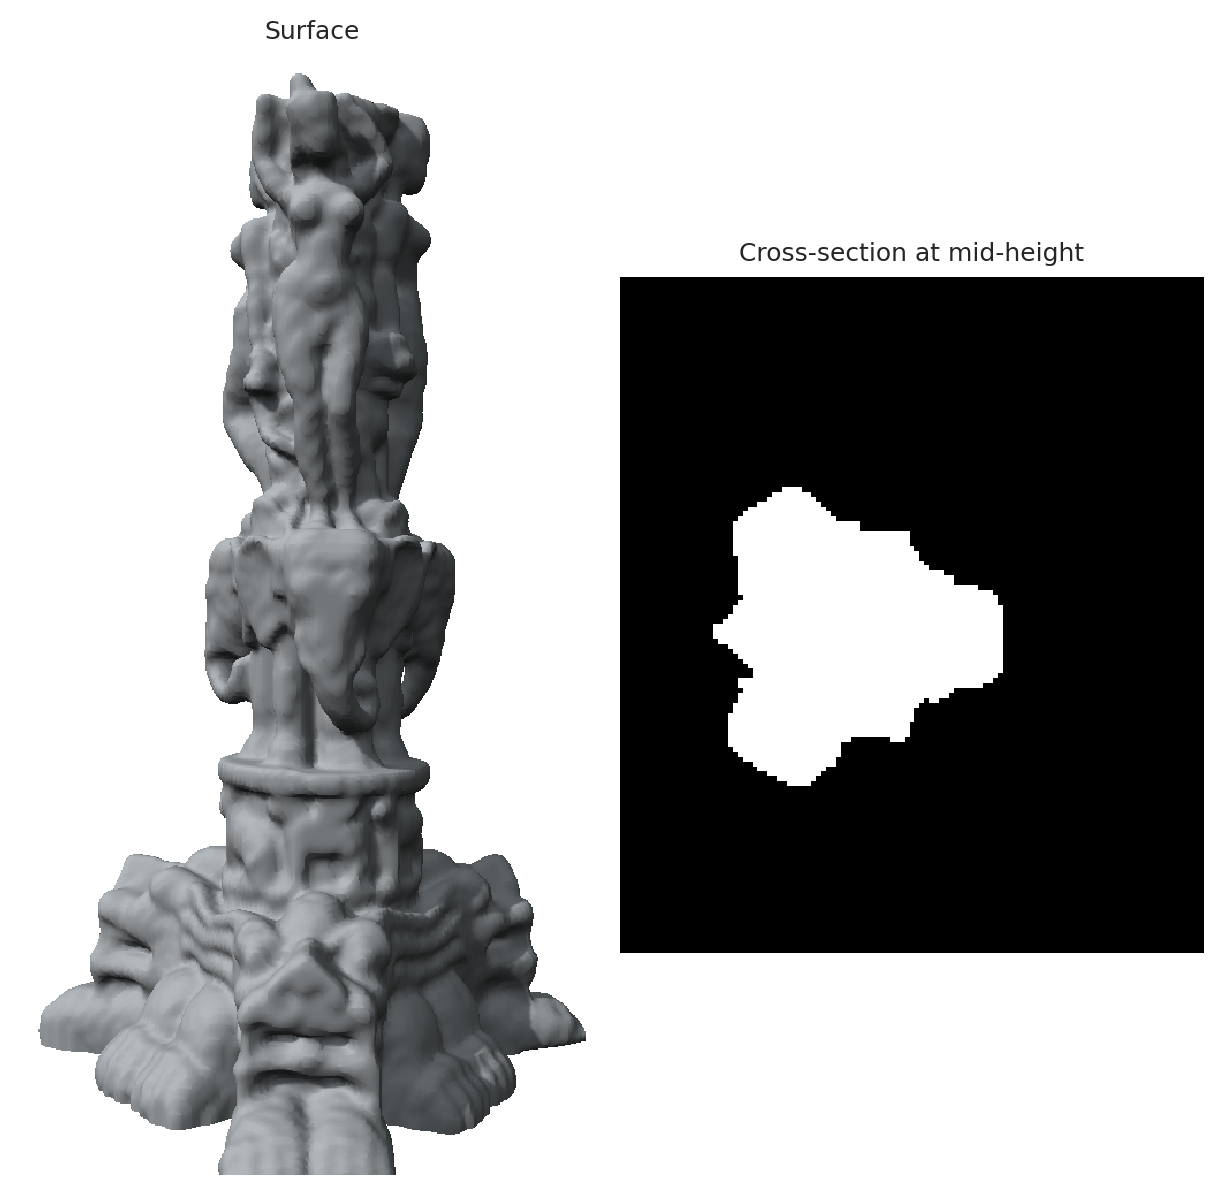

In [3]:
SHAPE = "thai_statue"
DATA_PATH = f"../data/occupancy/{SHAPE}.ply"
RESOLUTION = 256  # samples per unit length

volume = nf.OccupancyCoordinateDataset(DATA_PATH, resolution=RESOLUTION, item_id=SHAPE)
print(f"Voxel grid, cropped to the shape: {tuple(volume.grid_size)}")


def render(occupancy):
    """The rendered surface of an occupancy grid (1, D, H, W), as an RGB image."""
    with tempfile.TemporaryDirectory() as folder:
        path = Path(folder) / SHAPE
        volume.save(occupancy, path)
        return np.asarray(Image.open(path.with_suffix(".png")).convert("RGB"))


shape = render(volume.original)
drawn = np.nonzero(shape.min(-1) < 250)  # the rows and columns the surface covers
FRAME = tuple(slice(max(i.min() - 16, 0), i.max() + 17) for i in drawn)
# The grid's axis 1 points up, as the render draws it.
section = volume.original[0, :, volume.grid_size[1] // 2].numpy()

show(
    [("Surface", shape[FRAME]), ("Cross-section at mid-height", section)],
    ncols=2,
    width=6,
    cmap="gray",
)
plt.show()

## Models

Each entry gives a model's class, its arguments and its learning rate.
`# deviation` marks a setting that departs from the authors' code, with the
reason.

In [4]:
# FUTON: half the voxels along each axis of the cropped grid, and the largest
# rank, a multiple of 5, that keeps it smaller than every baseline (131,457
# parameters for the smallest); rank R costs R * sum(K) factor entries and R * 64
# in the hidden layer of the decoder, whose bias and output layer add 2 * 64 + 1.
COMPONENTS = [size // 2 for size in volume.grid_size]
RANK = (131_456 - 129) // (sum(COMPONENTS) + 64) // 5 * 5

CONFIGS = [
    {
        "name": "RFF",  # Tancik et al. (NeurIPS 2020), 3D occupancy
        "class": nf.RFF,
        "kwargs": {
            "hidden_features": 188,
            "hidden_layers": 2,
            "num_frequencies": 256,
            "sigma": 6.0,  # sigma 12 on [0, 1] coordinates equals 6 on [-1, 1]
            "output_activation": torch.tanh,
        },
        "lr": 3e-3,
    },
    {
        "name": "SIREN",  # FINER benchmark
        "class": nf.SIREN,
        "kwargs": {
            "hidden_features": 256,
            "hidden_layers": 3,
            "omega": 30.0,
            "output_activation": torch.tanh,
        },
        "lr": 3e-3,
    },
    {
        "name": "FINER",  # FINER benchmark
        "class": nf.FINER,
        "kwargs": {
            "hidden_features": 256,
            "hidden_layers": 3,
            "omega": 30.0,
            "output_activation": torch.tanh,
        },
        "lr": 1e-3,
    },
    {
        "name": "Instant-NGP",  # instant-ngp configs/volume/base.json architecture
        "class": nf.InstantNGP,
        "kwargs": {
            "num_levels": 16,
            "features_per_level": 2,
            "log2_hashmap_size": 12,
            "base_resolution": 16,
            "max_resolution": RESOLUTION,
            # deviation: 64 in the reference; the hash tables fill the budget
            "hidden_features": 32,
            "hidden_layers": 2,
            "output_activation": torch.tanh,
        },
        "lr": 3e-2,  # deviation: 1e-4 in the reference, for longer training
    },
    {
        "name": "TensoRF",
        "class": nf.TensoRF,
        "kwargs": {
            # a VM plane costs resolution^2 parameters per rank, so resolution
            # beats rank at this size
            "rank": 4,
            "resolution": 97,
            "mode": "vm",
            "hidden_features": 128,
            "hidden_layers": 2,
            "output_activation": torch.tanh,
        },
        "lr": 1e-2,  # 3e-2 never leaves the empty solution on lucy
    },
    {
        "name": "FUTON (sinc)",
        "class": nf.FUTON,
        "kwargs": {
            "basis": ("sinc", {"num_components": COMPONENTS, "grid_size": volume.grid_size}),
            "combiner": ("cp", {"rank": RANK}),
            "decoder": ("mlp", {"hidden_layers": 1, "hidden_features": 64}),
            "output_activation": torch.tanh,
        },
        "lr": 3e-2,
    },
    {
        "name": "FUTON (cosine)",
        "class": nf.FUTON,
        "kwargs": {
            "basis": ("cosine", {"num_components": COMPONENTS, "grid_size": volume.grid_size}),
            "combiner": ("cp", {"rank": RANK}),
            "decoder": ("mlp", {"hidden_layers": 1, "hidden_features": 64}),
            "output_activation": torch.tanh,
        },
        "lr": 3e-2,
    },
]

## Training

Every model is compiled with `torch.compile`, and an untimed forward and
backward pass compiles it before training starts. The training times exclude
that compilation and the evaluations.

In [5]:
CHUNK = 2**18  # voxels per forward pass when evaluating
train_dataset = nf.OccupancyCoordinateDataset(
    DATA_PATH, resolution=RESOLUTION, max_samples=2**18, item_id=SHAPE
)
results = {}

for config in CONFIGS:
    torch.manual_seed(0)
    model = config["class"](in_features=3, out_features=1, **config["kwargs"])
    print(f"{config['name']}: {nf.count_parameters(model):,} parameters")
    model.to(device).compile()
    model(train_dataset[0]["input"][None].to(device)).sum().backward()  # compiles it
    model.zero_grad(set_to_none=True)
    result = nf.train(
        model,
        train_dataset,
        volume,
        lr=config["lr"],
        num_steps=1000,
        metrics={"iou": nf.iou},
        log_interval=50,
        eval_interval=50,
        chunk_size=CHUNK,
        device=device,
        **config.get("train_kwargs", {}),
    )
    output = nf.chunked_inference(model, volume.input, chunk_size=CHUNK, device=device)
    result["reconstruction"] = volume.postprocess(output.cpu())
    results[config["name"]] = result

    del model, result["model_dict"]
    torch.cuda.empty_cache()
    torch.compiler.reset()  # the next model compiles anew

RFF: 132,165 parameters


SIREN: 132,865 parameters


FINER: 132,865 parameters


Instant-NGP: 133,152 parameters


TensoRF: 132,377 parameters


FUTON (sinc): 130,604 parameters


FUTON (cosine): 130,604 parameters


## Convergence

The IoU of the whole grid, every 50 steps.

FUTON is black, its cosine basis dashed; the periodic activations have warm
hues and the grids cool ones.

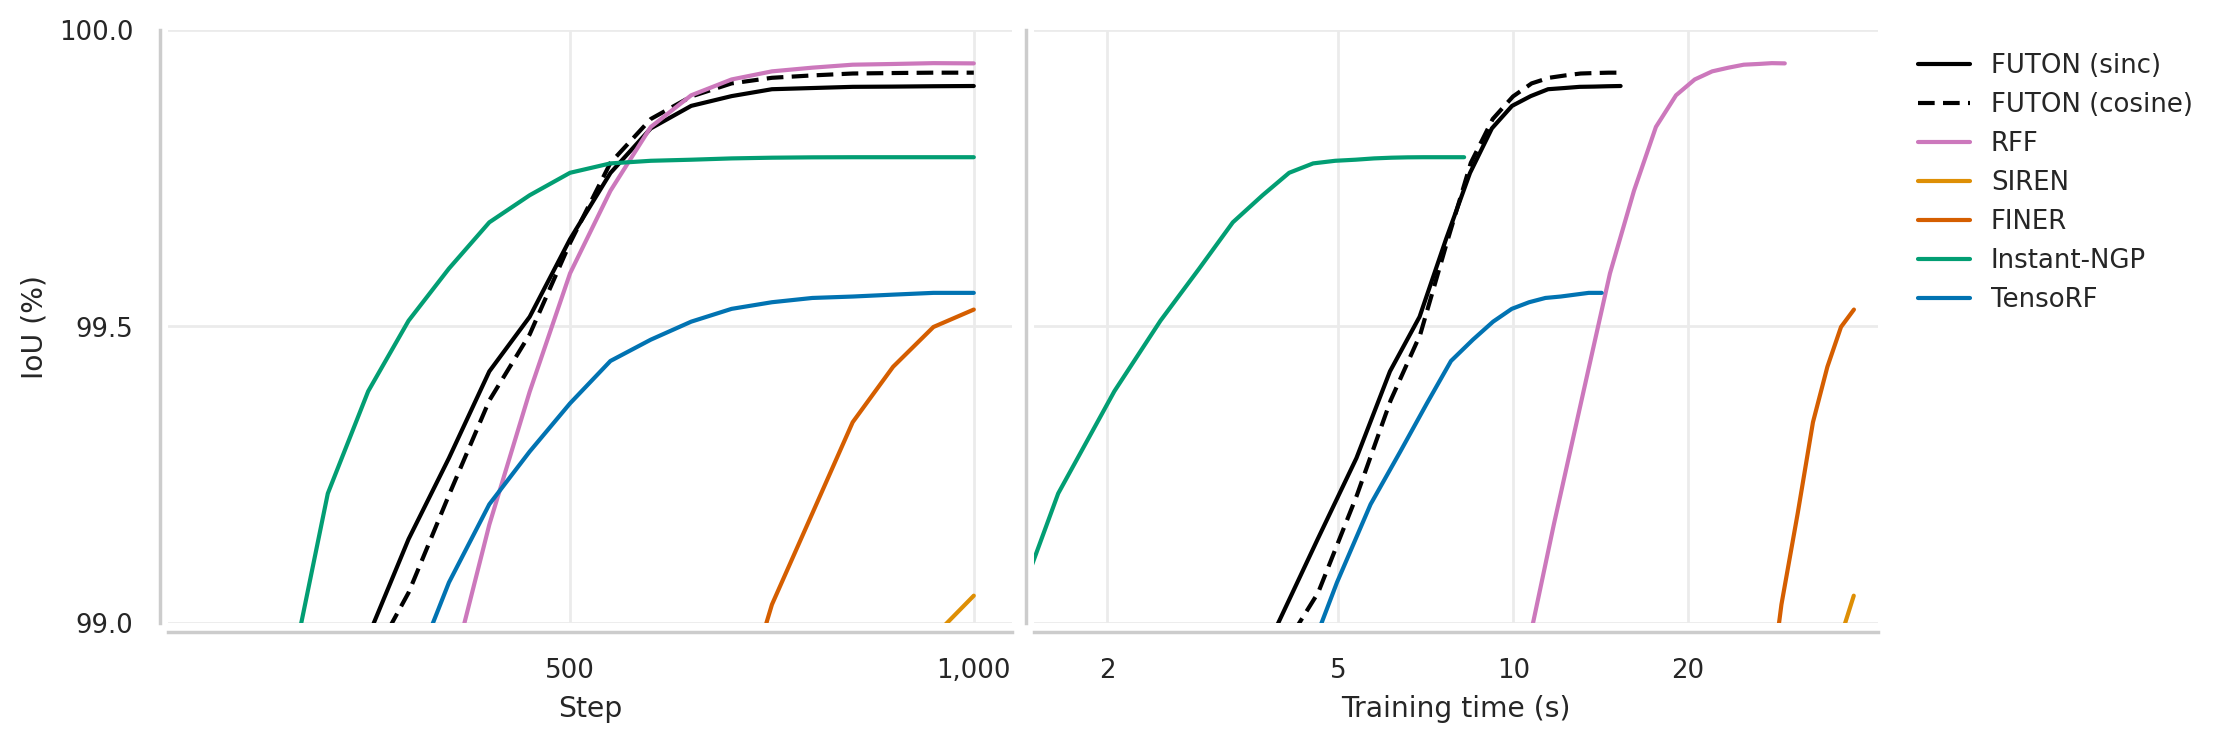

In [6]:
records = pd.DataFrame(
    {
        "Model": name,
        "Step": entry["step"],
        "Time (s)": entry["elapsed"],
        "IoU (%)": 100 * entry["eval"]["iou"],
    }
    for name, result in results.items()
    for entry in result["history"]
    if "eval" in entry
)

order = [model for model in PALETTE if model in set(records["Model"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, x in zip(axes, ("Step", "Time (s)")):
    sns.lineplot(
        records,
        x=x,
        y="IoU (%)",
        hue="Model",
        style="Model",
        hue_order=order,
        style_order=order,
        palette=PALETTE,
        dashes=DASHES,
        legend=ax is axes[1],
        ax=ax,
    )
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5, steps=NICE))
axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
final = records.groupby("Model")["IoU (%)"].last()
low, high = final.min(), records["IoU (%)"].max()
margin = 0.05 * (high - low)  # so that no curve ends on the frame
metric_axis(axes[0], "IoU (%)", low - margin, high + margin)
shown = records["IoU (%)"] >= axes[0].get_ylim()[0]  # the evaluations in view
time_axis(axes[1], records.loc[shown, "Time (s)"])

sns.move_legend(
    axes[-1], "upper left", bbox_to_anchor=(1.02, 1), title=None, frameon=False
)
sns.despine(fig, offset=3)
plt.show()

## Summary

Throughput is the median rate of the evaluations, which reconstruct the whole
grid, and inference memory their median peak; training memory is the peak
of training. In each column the best value is bold and the second
underlined.

In [7]:
rows = []
for name, result in results.items():
    evaluations = [entry["eval"] for entry in result["history"] if "eval" in entry]
    duration = np.median([e["duration"] for e in evaluations])
    memory = np.median([e["peak_memory"] for e in evaluations])
    rows.append(
        {
            "Model": name,
            "Params (k)": result["config"]["num_params"] / 1e3,
            "Training time (s)": result["history"][-1]["elapsed"],
            "Training memory (MB)": result["config"]["peak_memory"] / 1e6,
            "Throughput (MVox/s)": np.prod(volume.grid_size) / duration / 1e6,
            "Inference memory (MB)": memory / 1e6,
            "IoU (%)": 100 * evaluations[-1]["iou"],
        }
    )
summary = pd.DataFrame(rows).sort_values("IoU (%)", ascending=False)
formats = {
    "Params (k)": "{:.1f}",
    "Training time (s)": "{:.1f}",
    "Training memory (MB)": "{:.0f}",
    "Throughput (MVox/s)": "{:.1f}",
    "Inference memory (MB)": "{:.0f}",
    "IoU (%)": "{:.2f}",
}
better = {
    "Training time (s)": "lower",
    "Training memory (MB)": "lower",
    "Throughput (MVox/s)": "higher",
    "Inference memory (MB)": "lower",
    "IoU (%)": "higher",
}
table(summary, formats, better)

Model,Params (k),Training time (s),Training memory (MB),Throughput (MVox/s),Inference memory (MB),IoU (%)
RFF,132.2,29.3,1038,18.5,819,99.94
FUTON (cosine),130.6,15.4,530,50.6,527,99.93
FUTON (sinc),130.6,15.3,530,50.6,527,99.91
Instant-NGP,133.2,8.2,528,39.9,718,99.79
TensoRF,132.4,14.2,438,55.4,282,99.56
FINER,132.9,38.6,1619,18.7,551,99.53
SIREN,132.9,38.6,1619,18.8,551,99.05


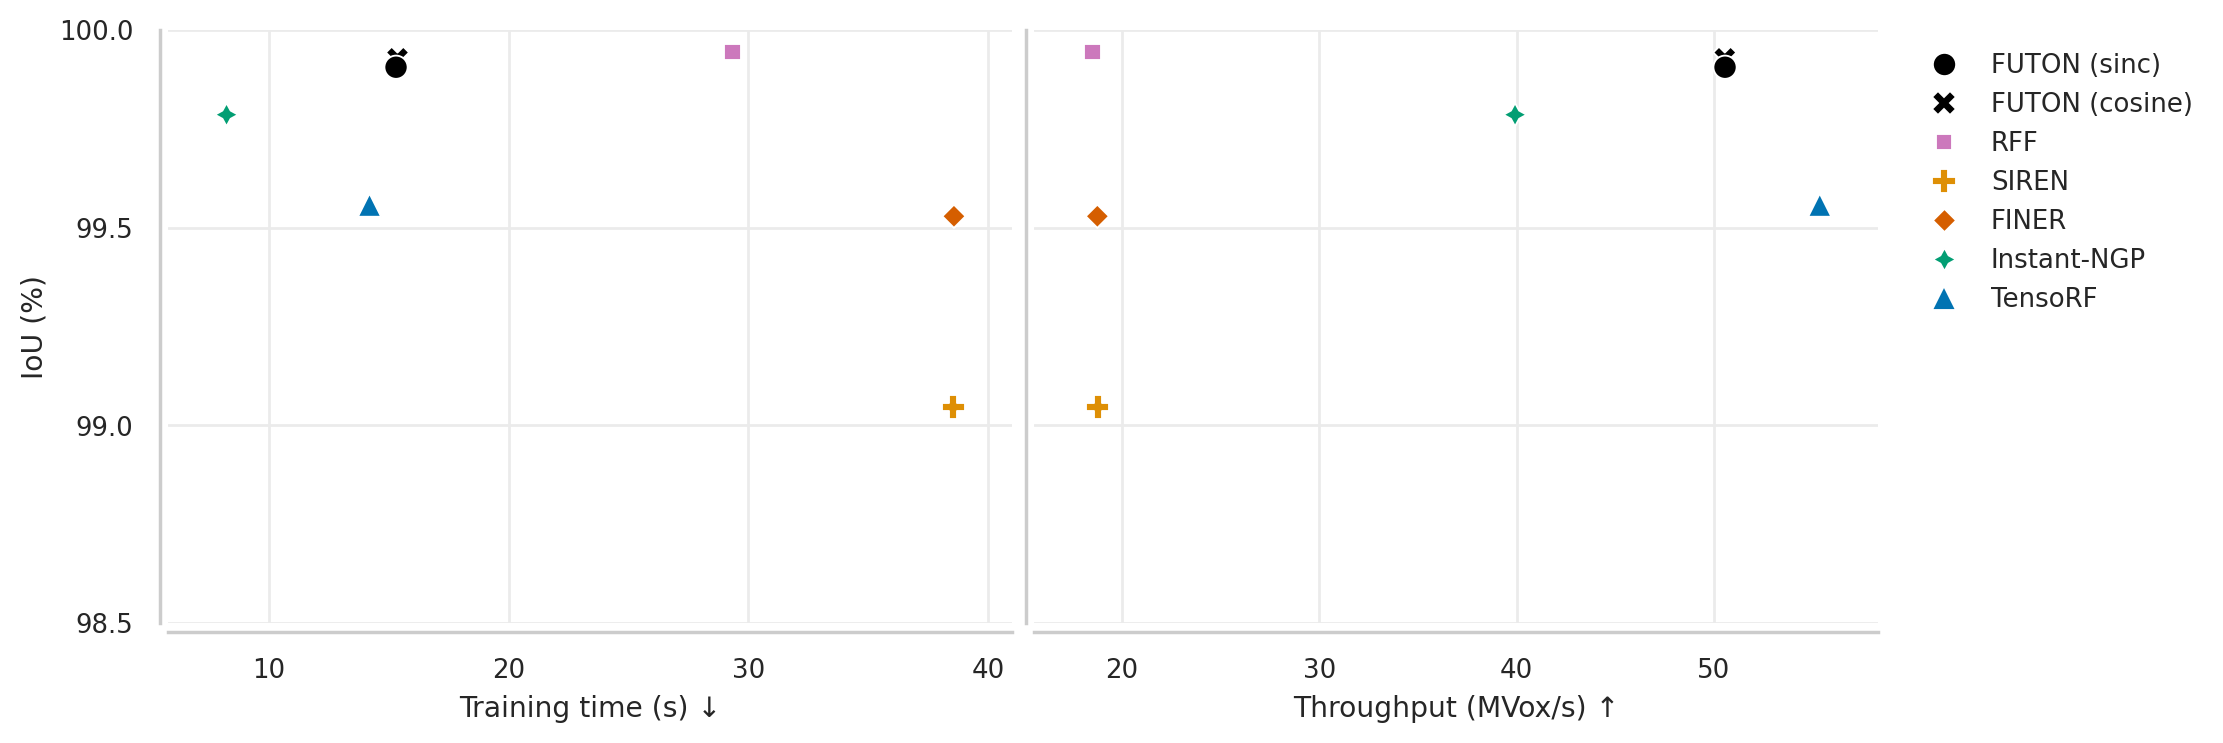

In [8]:
order = [model for model in PALETTE if model in set(summary["Model"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, cost in zip(axes, ("Training time (s)", "Throughput (MVox/s)")):
    sns.scatterplot(
        summary,
        x=cost,
        y="IoU (%)",
        hue="Model",
        style="Model",
        hue_order=order,
        style_order=order,
        palette=PALETTE,
        markers=MARKERS,
        s=70,
        legend=ax is axes[1],
        ax=ax,
    )
    ax.margins(x=0.08)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, steps=NICE))
axes[0].set_xlabel("Training time (s) ↓")
axes[1].set_xlabel("Throughput (MVox/s) ↑")
low, high = summary["IoU (%)"].min(), summary["IoU (%)"].max()
metric_axis(axes[0], "IoU (%)", low - 0.08 * (high - low), high + 0.08 * (high - low))

sns.move_legend(
    axes[-1], "upper left", bbox_to_anchor=(1.02, 1), title=None, frameon=False
)
sns.despine(fig, offset=3)
plt.show()

## Qualitative Comparison

The surface every reconstruction bounds, titled with its IoU.

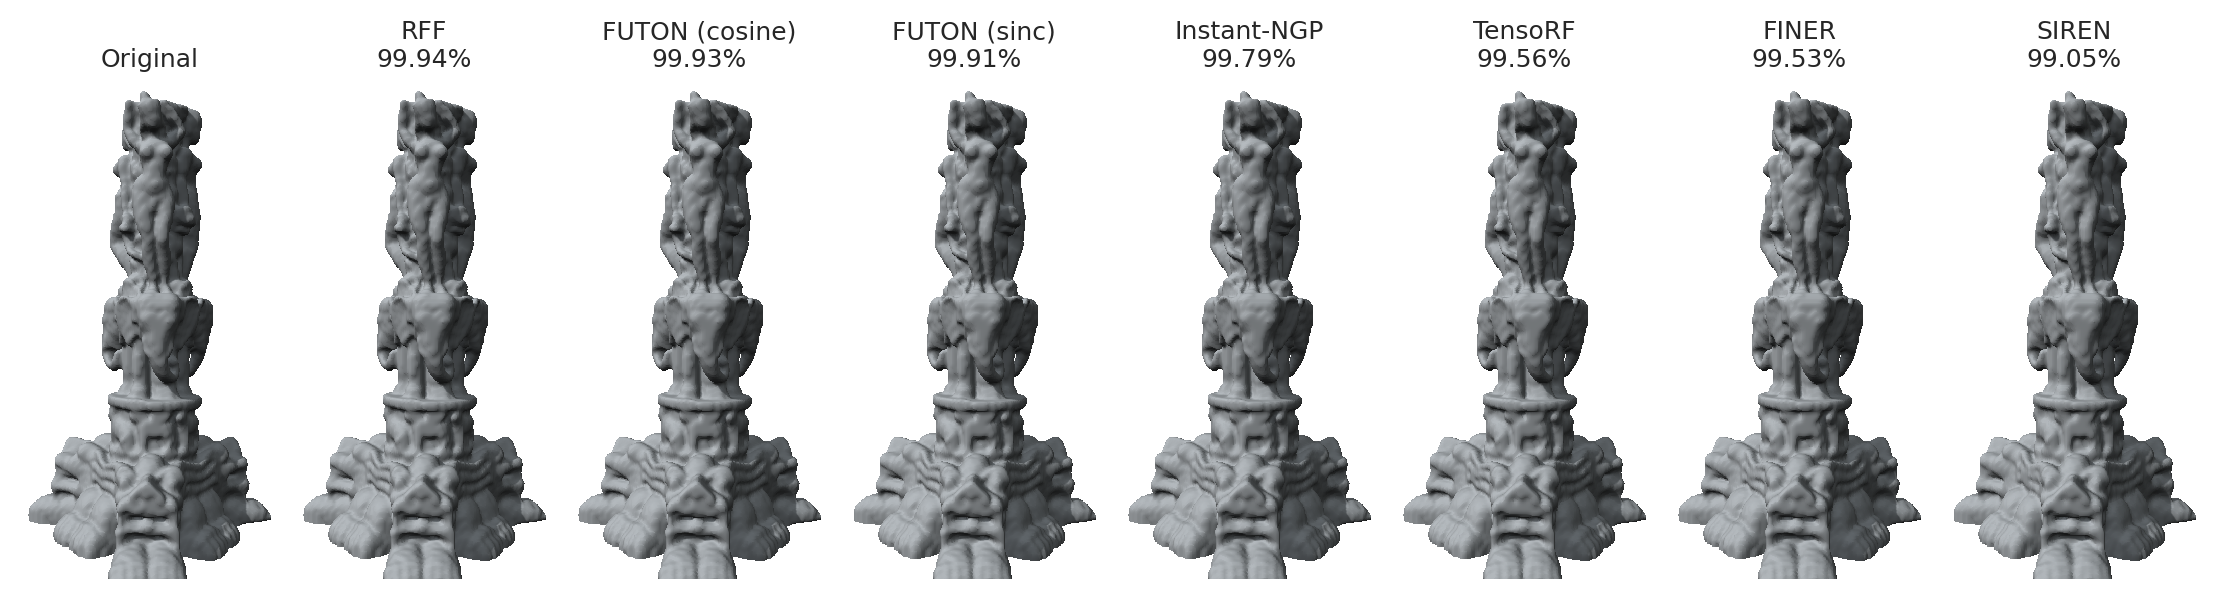

In [9]:
panels = [("Original", shape[FRAME])] + [
    (f"{name}\n{iou:.2f}%", render(results[name]["reconstruction"])[FRAME])
    for name, iou in zip(summary["Model"], summary["IoU (%)"])
]
show(panels, ncols=8)
plt.show()